# Forecasting a London household's next 24 hours of electricity use with an LSTM and a GRU

**Patrick Gilliland**, AI Mastery Capstone: Deep Learning Systems

This is a sequential or time-series task using a Recurrent Neural Network (RNN). From one household's previous seven days of half-hourly readings, the notebook forecasts that household's next 24 hours (48 half-hourly readings, in kWh). Two recurrent models make the forecast, and they differ only in the layer type: the baseline model (the LSTM) and the experimental model (the GRU). The data is the Low Carbon London smart meter data (UK Power Networks), 1,000 households from 2013. The report ships as `Deep_Learning_Systems_Analysis_Report.pdf` and, with the same content, as `module_summary.pdf`.

**Setup notes**

| Item | This notebook |
|---|---|
| Rig | NVIDIA GeForce RTX 5090, Linux under WSL2 |
| Python | 3.12.3 |
| PyTorch | 2.14.1 from PyPI |
| CUDA | 13.0 (the runtime PyTorch ships with), cuDNN 9.24.0 |
| Training time on the GPU, last full run | [TO FILL from the Phase 2 full run] |
| Estimated training time on a CPU | [TO FILL from the Phase 2 full run] |

Both times come from the last full run of this notebook, and the code prints them in Task 5's timing table. With no GPU visible, the same code runs on the CPU.

**Setup.** The first code cell sets two environment variables before PyTorch loads, seeds every random number generator, fixes the settings that make a rerun repeat its numbers, caps the GPU's memory when there is a GPU, and defines the training watchdog that Task 3 uses.

In [1]:
import hashlib
import math
import os
import platform
import random
import re
import statistics

# A value set outside the notebook wins, so CUDA_VISIBLE_DEVICES set to an empty string hides
# the GPU for a CPU run. The cuBLAS setting is the one PyTorch's nn.LSTM page gives for
# repeatable recurrent layers on a GPU.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:2")

import numpy as np  # noqa: E402
import torch  # noqa: E402

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Deterministic cuDNN kernels and no TF32, so a rerun gives the same numbers and the arithmetic
# stays float32.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

on_gpu = torch.cuda.is_available()
if on_gpu:
    # Half the card at most, by this rig's GPU rules.
    torch.cuda.set_per_process_memory_fraction(0.5)


def watchdog(epoch_seconds, loss, elapsed_seconds, on_gpu, factor=3.0, limit_seconds=7200.0):
    """Return why a training run should stop, or None to carry on.

    epoch_seconds lists each finished epoch's seconds, the latest last. A NaN or infinite loss
    stops a run on any device. On the GPU, an epoch slower than factor times the median of the
    epochs before it, or a run past limit_seconds, also stops it. On a CPU the run goes to the
    end, because a grader's CPU run is meant to finish.
    """
    if not math.isfinite(loss):
        return f"loss is {loss}"
    if not on_gpu:
        return None
    if elapsed_seconds > limit_seconds:
        return f"the run passed {limit_seconds / 3600:g} hours"
    if len(epoch_seconds) > 1:
        line = factor * statistics.median(epoch_seconds[:-1])
        if epoch_seconds[-1] > line:
            return f"the epoch took {epoch_seconds[-1]:.1f} s, over {line:.1f} s"
    return None


print(f"Python {platform.python_version()}, PyTorch {torch.__version__}, NumPy {np.__version__}")
print(f"Platform: {platform.platform()}")
print(f"Seed: {SEED}")
print(f"CUDA_VISIBLE_DEVICES={os.environ['CUDA_VISIBLE_DEVICES']!r}, "
      f"CUBLAS_WORKSPACE_CONFIG={os.environ['CUBLAS_WORKSPACE_CONFIG']!r}")
if on_gpu:
    cudnn = torch.backends.cudnn.version()
    print(f"Device: cuda, {torch.cuda.get_device_name(0)}, CUDA {torch.version.cuda}, "
          f"cuDNN {cudnn // 10000}.{cudnn % 10000 // 100}.{cudnn % 100}")
    print("GPU memory cap: half the card")
else:
    print("Device: cpu, no GPU visible, so the watchdog lets a run go to the end")

Python 3.12.3, PyTorch 2.14.1+cu130, NumPy 2.5.4
Platform: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
Seed: 42
CUDA_VISIBLE_DEVICES='0', CUBLAS_WORKSPACE_CONFIG=':4096:2'
Device: cuda, NVIDIA GeForce RTX 5090, CUDA 13.0, cuDNN 9.24.0
GPU memory cap: half the card


**Environment check.** The brief's own validation code, as given, reading this project's data file. In one cell only the last line's value is shown, so `device` on its own line prints nothing here; the setup cell above prints the device.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device
df = pd.read_csv("lcl_2013_1000_households.csv.gz")
df.head()

,LCLid,tariff_group,date,price_signal,r00,r01,r02,r03,r04,r05,...,r38,r39,r40,r41,r42,r43,r44,r45,r46,r47
0,MAC000006,Std,2013-01-01,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.044,0.044,0.043,0.044,0.030,0.0,0.0,0.0,0.0,0.0
1,MAC000006,Std,2013-01-02,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.044,0.043,0.043,0.044,0.029,0.0,0.0,0.0,0.0,0.0
2,MAC000006,Std,2013-01-03,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.043,0.043,0.043,0.024,0.0,0.0,0.0,0.0,0.0
3,MAC000006,Std,2013-01-04,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.044,0.043,0.043,0.030,0.0,0.0,0.0,0.0,0.0
4,MAC000006,Std,2013-01-05,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.043,0.043,0.043,0.030,0.0,0.0,0.0,0.0,0.0


## Task 1: Define the Problem and Choose Your Dataset

**Goal.** Show where the data came from and what the pipeline did to it, from the manifest the pipeline wrote. Then state the task, the question, and why the dataset meets each of the brief's rules.

In [3]:
def manifest_tables(text):
    """Return the tables in MANIFEST.md text, keyed by the heading of the section they sit in.

    Each value is a list of that section's tables, in order, as DataFrames of strings. A section
    with no table is left out.
    """
    tables, heading, rows = {}, None, []
    for line in text.splitlines() + [""]:
        if line.startswith("|"):
            rows.append([cell.strip() for cell in line.strip().strip("|").split("|")])
            continue
        if rows and heading is not None:
            separator = all(re.fullmatch(r":?-+:?", cell) for cell in rows[1])
            body = rows[2:] if separator else rows[1:]
            tables.setdefault(heading, []).append(pd.DataFrame(body, columns=rows[0]))
        rows = []
        if line.startswith("## "):
            heading = line[3:].strip()
    return tables

In [4]:
with open("data_pipeline/MANIFEST.md", encoding="utf-8") as fh:
    manifest_text = fh.read()
manifest = manifest_tables(manifest_text)

print(next(line for line in manifest_text.splitlines() if line.startswith("Written by")))
for section in ["Source", "Files", "The publisher's figures beside the measured ones",
                "Pipeline steps", "Price signals"]:
    print(f"\n{section}")
    for table in manifest[section]:
        print(table.to_string(index=False))

steps = manifest["Pipeline steps"][0].set_index("Step")["Count"]
reading_columns = [column for column in df.columns if re.fullmatch(r"r\d\d", column)]
assert len(df) == int(steps["Output rows"].replace(",", "")), "the file and the manifest differ"
print(f"\nThe working file the validation cell loaded: {len(df):,} rows, as the manifest's output "
      f"rows; {len(reading_columns)} half-hourly readings a row ({len(reading_columns) / 2:g} "
      f"hours), {len(df) * len(reading_columns):,} readings in all")

Written by `data_pipeline/build_lcl_subset.py` on 2026-10-11, with Python 3.12.3, pandas 3.0.6 and NumPy 2.5.4. Year 2013, 1,000 households, seed 42, pool `strict`.

Source
         Item                                                                                           Value
     Data set                                         SmartMeter Energy Consumption Data in London Households
    Publisher                          UK Power Networks (Low Carbon London project), on the London Datastore
         Page              https://data.london.gov.uk/dataset/smartmeter-energy-use-data-in-london-households
      Licence          Creative Commons Attribution (CC BY 4.0), https://creativecommons.org/licenses/by/4.0/
Readings file https://data.london.gov.uk/download/vqm0d/3527bf39-d93e-4071-8451-df2ade1ea4f2/LCL-FullData.zip
  Tariff file     https://data.london.gov.uk/download/vqm0d/14855047-44c2-4856-8a48-e5649200e6ce/Tariffs.xlsx
   Downloaded                                            

**The task.** Of the brief's three task types, this is the second: "Sequential or time-series tasks using a Recurrent Neural Network (RNN)". The task is forecasting one household's next 24 hours (48 half-hourly readings), each a half-hourly reading in kWh.

**The question.** From one household's previous seven days of half-hourly readings, how well can a Recurrent Neural Network forecast its next 24 hours (48 half-hourly readings), and does the experimental model (the GRU) forecast better or worse than the baseline model (the LSTM) when the layer type is the only change?

**The dataset.**

| Item | Value |
|---|---|
| Name | SmartMeter Energy Consumption Data in London Households: the Low Carbon London smart meter data (UK Power Networks) |
| Publisher | UK Power Networks (Low Carbon London project), on the London Datastore |
| Page | https://data.london.gov.uk/dataset/smartmeter-energy-use-data-in-london-households |
| Licence | Creative Commons Attribution (CC BY 4.0) |
| File | `lcl_2013_1000_households.csv.gz`, beside this notebook, built from the download by `data_pipeline/build_lcl_subset.py` |
| Size | 26,957,559 bytes (25.71 MiB) as gzip; the CSV inside is 113,142,976 bytes |
| SHA-256 | `9fd762e499e60c7bc17db319282707b34864f8b9a3478dd872d9c2037a399c49` |
| Downloaded | 11 October 2026 |

**Why it meets each of the brief's rules.**

- "Be appropriate for deep learning in your chosen domain": each household's readings are an ordered series at a fixed half-hourly step, the kind of sequence a Recurrent Neural Network reads one step at a time.
- "Contain enough samples to support training and evaluation": 1,000 households over a whole year give 365,000 household-days and 17,520,000 readings. Task 2 counts the household-days in the training, validation and test months.
- "Be publicly available and appropriate for academic use": the London Datastore publishes it under the Creative Commons Attribution licence, which allows reuse with credit.
- "Not be synthetic or AI-generated": the publisher describes the readings as "Energy consumption readings for a sample of 5,567 London Households that took part in the UK Power Networks led Low Carbon London project", so they are the trial's own meter readings.
- "Not be reused from any previous capstone project": the earlier capstone projects used Birmingham City Council purchase card data, the GOV.UK payment practices reports and the Department for Transport's spending data. None of them comes from UK Power Networks.

**How the subset was obtained and prepared.**

1. `LCL-FullData.zip` and `Tariffs.xlsx` were downloaded from the page above on 11 October 2026. The zip is compressed with Deflate64, which Python's `zipfile` cannot open, so `CC_LCL-FullData.csv` is extracted first with a tool that handles it, such as Info-ZIP `unzip` or 7-Zip.
2. `data_pipeline/build_lcl_subset.py`, which uses only the standard library and pandas, then dropped the 5,560 "Null" readings (the same 5,560 rows are stamped off the half-hour grid), kept one of each exact duplicate (115,453 dropped), and kept the 93,024,217 readings stamped in 2013.
3. It found the 1,132 households with every 2013 reading (881 in the standard tariff group, 251 in the time-of-use group) and drew 1,000 of them with seed 42: 781 in the standard tariff group and 219 in the time-of-use group.
4. It wrote one row per household-day: `LCLid` (the household), `tariff_group` (the data's `Std` or `ToU`), `date`, `price_signal` (none, high, low or both on a time-of-use household's day, from `Tariffs.xlsx`, and empty for the standard tariff group), then `r00` to `r47`, the day's 48 half-hourly readings in kWh as published.
5. The time stamps are kept as published, and they behave as GMT all year (Task 2 shows the summer shift this causes). The tariff file appears to follow the UK local clock, so the pipeline moves its summer stamps one hour back to match the readings; the manifest's last table lists the four half-hours that the move leaves with two tariff rows or none.

## Task 2: Load and Inspect Your Dataset

**Goal.** Load the working file, show what it holds with representative samples, show the shapes that go into a model and come out of it, and see how well three naive forecasts do on the validation months. The anomaly list follows.

In [5]:
DATA = "lcl_2013_1000_households.csv.gz"
files = manifest["Files"][0]
expected = files.loc[files["File"].str.contains("(the output)", regex=False), "SHA-256"].iloc[0]
with open(DATA, "rb") as fh:
    digest = hashlib.sha256(fh.read()).hexdigest()
assert digest == expected.strip("`"), (
    f"{DATA} is not the file the manifest describes; rebuild it with "
    "data_pipeline/build_lcl_subset.py")
print(f"{DATA}: SHA-256 {digest}, as the manifest gives")

df = pd.read_csv(DATA, dtype={"LCLid": str, "tariff_group": str, "date": str,
                              "price_signal": str}, keep_default_na=False)
print(f"Shape: {df.shape}")
df.head()

lcl_2013_1000_households.csv.gz: SHA-256 9fd762e499e60c7bc17db319282707b34864f8b9a3478dd872d9c2037a399c49, as the manifest gives


Shape: (365000, 52)


,LCLid,tariff_group,date,price_signal,r00,r01,r02,r03,r04,r05,...,r38,r39,r40,r41,r42,r43,r44,r45,r46,r47
0,MAC000006,Std,2013-01-01,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.044,0.044,0.043,0.044,0.030,0.0,0.0,0.0,0.0,0.0
1,MAC000006,Std,2013-01-02,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.044,0.043,0.043,0.044,0.029,0.0,0.0,0.0,0.0,0.0
2,MAC000006,Std,2013-01-03,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.043,0.043,0.043,0.024,0.0,0.0,0.0,0.0,0.0
3,MAC000006,Std,2013-01-04,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.044,0.043,0.043,0.030,0.0,0.0,0.0,0.0,0.0
4,MAC000006,Std,2013-01-05,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.043,0.043,0.043,0.030,0.0,0.0,0.0,0.0,0.0


In [6]:
labels = ["LCLid", "tariff_group", "date", "price_signal"]
print(df[labels].dtypes.to_string())
reading_types = ", ".join(str(t) for t in df[reading_columns].dtypes.unique())
print(f"{len(reading_columns)} reading columns, {reading_columns[0]} to {reading_columns[-1]}, "
      f"all {reading_types}\n")

groups = (df.groupby("tariff_group")
          .agg(households=("LCLid", "nunique"), days=("date", "size"))
          .rename(columns={"days": "household-days"}))
print(groups.to_string(formatters={"household-days": "{:,}".format}))

LCLid           str
tariff_group    str
date            str
price_signal    str
48 reading columns, r00 to r47, all float64

              households household-days
tariff_group                           
Std                  781        285,065
ToU                  219         79,935


In [7]:
def assign_split(dates):
    """Return "training", "validation" or "test" for each ISO date: the training months are
    1 Jan to 31 Aug 2013, the validation months 1 Sep to 31 Oct and the test months 1 Nov to
    31 Dec."""
    stamps = pd.to_datetime(pd.Series(dates), format="%Y-%m-%d")
    if (stamps.dt.year != 2013).any():
        raise ValueError("every date must fall in 2013")
    month = stamps.dt.month.to_numpy()
    return np.select([month <= 8, month <= 10], ["training", "validation"], default="test")

In [8]:
# Counted from the dates alone: no reading from the test months is used before Task 5.
split = assign_split(df["date"])
split_table = (pd.DataFrame({"split": split, "date": df["date"]})
               .groupby("split", sort=False)["date"]
               .agg(first="min", last="max", days="nunique", household_days="size")
               .rename(columns={"first": "first day", "last": "last day",
                                "household_days": "household-days"}))
print(split_table.to_string(formatters={"household-days": "{:,}".format}))

             first day    last day  days household-days
split                                                  
training    2013-01-01  2013-08-31   243        243,000
validation  2013-09-01  2013-10-31    61         61,000
test        2013-11-01  2013-12-31    61         61,000


In [9]:
rng = np.random.default_rng(SEED)
households = np.sort(rng.choice(np.asarray(df["LCLid"].unique()), size=3, replace=False))
sample_day = "2013-03-06"
assert assign_split([sample_day])[0] == "training"
samples = df[df["LCLid"].isin(households) & (df["date"] == sample_day)]
print(samples[labels].to_string(index=False), "\n")

stamps = [f"{i // 2:02d}:{30 * (i % 2):02d}" for i in range(48)]
shown = samples.set_index("LCLid")[reading_columns].T
shown.index = pd.Index(stamps, name="stamp (GMT)")
print(shown.to_string(float_format="{:.3f}".format))

    LCLid tariff_group       date price_signal
MAC000604          Std 2013-03-06             
MAC003848          ToU 2013-03-06         none
MAC004461          Std 2013-03-06              

LCLid        MAC000604  MAC003848  MAC004461
stamp (GMT)                                 
00:00            0.298      0.297      0.075
00:30            0.261      0.251      0.103
01:00            0.274      0.127      0.058
01:30            0.205      0.089      0.072
02:00            0.182      0.262      0.063
02:30            0.154      0.869      0.062
03:00            0.167      0.857      0.069
03:30            0.129      0.853      0.054
04:00            0.125      0.828      0.073
04:30            0.128      0.725      0.042
05:00            0.133      0.629      0.097
05:30            0.119      0.718      0.083
06:00            0.123      0.615      0.082
06:30            0.132      0.614      0.042
07:00            0.127      0.648      0.240
07:30            0.117      0.997      0.123


Figure 1: 2013-03-04 to 2013-03-10, households MAC000604, MAC003848, MAC004461


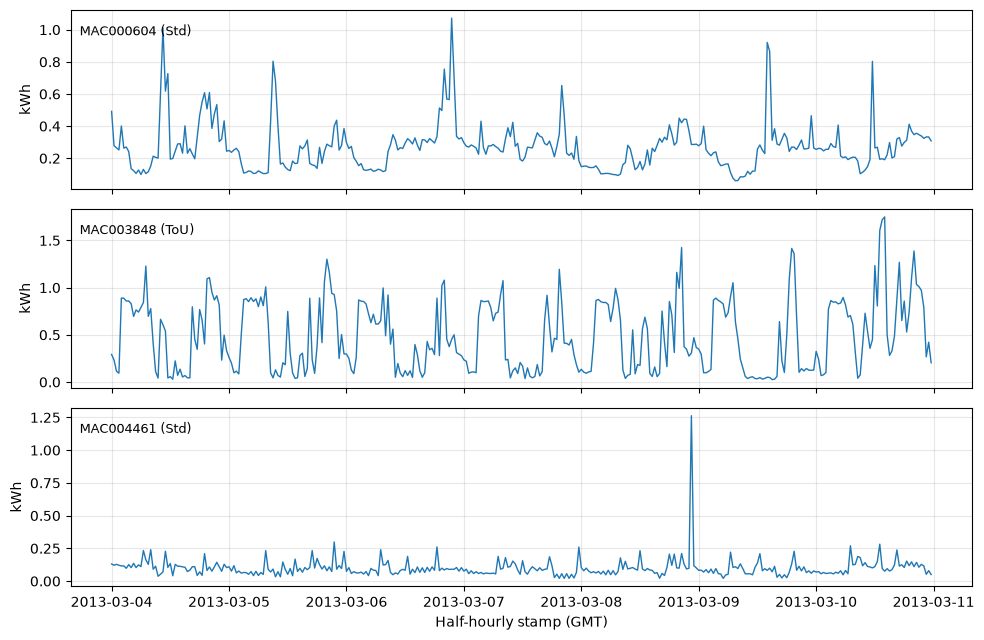

In [10]:
week = df[df["LCLid"].isin(households) & df["date"].between("2013-03-04", "2013-03-10")]
print(f"Figure 1: {week['date'].min()} to {week['date'].max()}, households "
      f"{', '.join(households)}")

fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
for ax, (household, rows) in zip(axes, week.groupby("LCLid")):
    values = rows[reading_columns].to_numpy().ravel()
    times = pd.date_range(rows["date"].iloc[0], periods=len(values), freq="30min")
    ax.plot(times, values, linewidth=1)
    ax.set_ylabel("kWh")
    ax.text(0.01, 0.92, f"{household} ({rows['tariff_group'].iloc[0]})",
            transform=ax.transAxes, va="top", fontsize=9)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Half-hourly stamp (GMT)")
fig.tight_layout()
plt.show()

**Figure 1.** One week of half-hourly readings, 2013-03-04 to 2013-03-10 (Monday to Sunday, in the training months, GMT stamps), for the three households drawn with seed 42, each named by its published pseudonymous `LCLid` and its tariff group. The three differ in level and in shape. MAC000604 has short peaks above a steady base, MAC003848 (the time-of-use group) switches between a low level and a high one through each day, and MAC004461 stays low apart from one short spike. One model has to forecast all three kinds.

In [11]:
def to_cube(frame, columns):
    """Return the household IDs, the dates and the readings as an array of shape
    (households, days, len(columns)), from a frame with one row per household-day, sorted by
    household and then date, every household holding the same dates."""
    ids = frame["LCLid"].drop_duplicates().to_numpy()
    if len(frame) % len(ids):
        raise ValueError("the households hold different numbers of days")
    n_days = len(frame) // len(ids)
    who = frame["LCLid"].to_numpy().reshape(len(ids), n_days)
    when = frame["date"].to_numpy().reshape(len(ids), n_days)
    if (who != ids[:, None]).any() or (when != when[0]).any():
        raise ValueError("each household needs the same dates, in one block of rows")
    if list(ids) != sorted(ids) or list(when[0]) != sorted(when[0]):
        raise ValueError("the rows must be sorted by household and then date")
    values = frame[columns].to_numpy(dtype=float).reshape(len(ids), n_days, len(columns))
    return ids, when[0].copy(), values

In [12]:
def cut_window(series, target_day, input_days=7, per_day=48):
    """Return one window from a household's readings in time order: the input, the
    input_days * per_day readings before the target day, shaped (steps, 1), and the target,
    the per_day readings of the target day."""
    start, end = (target_day - input_days) * per_day, (target_day + 1) * per_day
    if start < 0 or end > len(series):
        raise ValueError("the window must lie inside the series")
    x = np.array(series[start:target_day * per_day], dtype=float).reshape(-1, 1)
    y = np.array(series[target_day * per_day:end], dtype=float)
    return x, y

In [13]:
households_all, days, cube = to_cube(df, reading_columns)
print(f"Readings as an array of households, days and half-hours: {cube.shape}")

target = 7
x, y = cut_window(cube[0].ravel(), target)
print(f"\nOne window for {households_all[0]}:")
print(f"  input, {days[target - 7]} 00:00 to {days[target - 1]} 23:30: shape "
      f"{torch.from_numpy(x).float().shape}")
print(f"  target (the labels), {days[target]} 00:00 to {days[target]} 23:30: shape "
      f"{torch.from_numpy(y).float().shape}")
print("  last six input readings:", np.round(x[-6:, 0], 3))
print("  target readings:", np.round(y, 3))

Readings as an array of households, days and half-hours: (1000, 365, 48)

One window for MAC000006:
  input, 2013-01-01 00:00 to 2013-01-07 23:30: shape torch.Size([336, 1])
  target (the labels), 2013-01-08 00:00 to 2013-01-08 23:30: shape torch.Size([48])
  last six input readings: [0.024 0.    0.    0.    0.    0.   ]
  target readings: [0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.024 0.044 0.044 0.044 0.044 0.03  0.    0.    0.    0.
 0.    0.    0.144 0.067 0.067 0.06  0.043 0.115 0.078 0.037 0.073 0.036
 0.083 0.085 0.088 0.066 0.037 0.071 0.015 0.049 0.014 0.05  0.047 0.299]


**Inputs and labels.** A forecast has no class labels. Its labels are its targets: the 48 half-hourly readings of the day after the input week. One window is a household's 336 readings over seven days, shaped (336, 1) because each step carries one feature, the reading in kWh. Its target is shaped (48,) because the model forecasts all 48 readings at once. The array above holds every reading as households by days by half-hours, so windows can be cut from it when needed rather than stored. Task 3 cuts the windows for every household and target day, counts them in each split, and fits the scaler on the training months only. The file loads as float64, and the models will train in float32.

**Naive forecasts on the validation months.** Three naive forecasts show the level a model has to beat. Each forecasts a target day at 00:00 from earlier days only: the same half-hour yesterday, the same half-hour last week, and the mean of the previous 7 days at each half-hour. They are scored here on the validation months (1 Sep to 31 Oct 2013) only. The test months stay unread until Task 5.

The metrics:

- MAE in kWh per half-hour: the mean absolute error over every household and half-hour;
- MAE divided by mean use: the MAE over the mean reading, so that months with different levels of use can be compared;
- MASE per household: each household's MAE divided by the MAE of the same half-hour yesterday on that household's training months (1 Jan to 31 Aug 2013), given as the mean and the median over households (Hyndman & Koehler, 2006);
- RMSE in kWh per half-hour, which weighs large errors more.

In [14]:
def naive_forecasts(cube, target_days):
    """Return the three naive forecasts for each target day, made from earlier days only, each
    shaped (households, len(target_days), 48): the same half-hour yesterday, the same half-hour
    last week, and the mean of the previous 7 days at each half-hour."""
    target_days = np.asarray(target_days)
    if target_days.min() < 7:
        raise ValueError("every target day needs seven earlier days")
    return {
        "same half-hour yesterday": cube[:, target_days - 1],
        "same half-hour last week": cube[:, target_days - 7],
        "mean of the previous 7 days": np.stack(
            [cube[:, day - 7:day].mean(axis=1) for day in target_days], axis=1),
    }

In [15]:
def insample_scale(cube, days, lag=48):
    """Return each household's MASE scale: the MAE of the same half-hour yesterday inside the
    given consecutive days, every reading against the one lag readings before it."""
    days = np.asarray(days)
    if np.any(np.diff(days) != 1):
        raise ValueError("the days must be consecutive")
    series = cube[:, days].reshape(len(cube), -1)
    return np.abs(series[:, lag:] - series[:, :-lag]).mean(axis=1)

In [16]:
def forecast_scores(actual, forecast, scale):
    """Return MAE, MAE divided by mean use, MASE per household (mean and median) and RMSE for
    forecasts against actual readings, both shaped (households, days, 48). scale holds each
    household's MASE scale; a household whose scale is zero has no MASE and is left out of it."""
    error = forecast - actual
    mae = np.abs(error).mean()
    household_mae = np.abs(error).mean(axis=(1, 2))
    mase = household_mae[scale > 0] / scale[scale > 0]
    return {
        "MAE (kWh per half-hour)": mae,
        "MAE divided by mean use": mae / actual.mean(),
        "MASE per household, mean": mase.mean() if mase.size else np.nan,
        "MASE per household, median": np.median(mase) if mase.size else np.nan,
        "RMSE (kWh per half-hour)": np.sqrt((error ** 2).mean()),
    }

In [17]:
day_split = assign_split(days)
training_days = np.flatnonzero(day_split == "training")
validation_days = np.flatnonzero(day_split == "validation")

scale = insample_scale(cube, training_days)
actual = cube[:, validation_days]
naive = naive_forecasts(cube, validation_days)
naive_table = pd.DataFrame({name: forecast_scores(actual, forecast, scale)
                            for name, forecast in naive.items()}).T

print(f"Validation months: {days[validation_days[0]]} to {days[validation_days[-1]]}, "
      f"{len(validation_days)} target days, {len(actual):,} households")
print(f"Mean use on the validation months: {actual.mean():.4f} kWh per half-hour")
print(f"MASE scale from the training months, {days[training_days[0]]} to "
      f"{days[training_days[-1]]}: households with a zero scale {int((scale == 0).sum())}\n")
print(naive_table.round(4).to_string())

Validation months: 2013-09-01 to 2013-10-31, 61 target days, 1,000 households
Mean use on the validation months: 0.1955 kWh per half-hour
MASE scale from the training months, 2013-01-01 to 2013-08-31: households with a zero scale 0

                             MAE (kWh per half-hour)  MAE divided by mean use  MASE per household, mean  MASE per household, median  RMSE (kWh per half-hour)
same half-hour yesterday                      0.1147                   0.5864                    0.9534                      0.9572                    0.2434
same half-hour last week                      0.1165                   0.5961                    0.9688                      0.9572                    0.2451
mean of the previous 7 days                   0.0962                   0.4922                    0.7994                      0.7934                    0.1911


In [18]:
group = (df.groupby("LCLid")["tariff_group"].first()
         .reindex(households_all).to_numpy())
by_group = {}
for name, forecast in naive.items():
    row = {}
    for metric in ["MAE divided by mean use", "MAE (kWh per half-hour)",
                   "MASE per household, median"]:
        for tariff in ["Std", "ToU"]:
            mine = group == tariff
            row[(metric, tariff)] = forecast_scores(actual[mine], forecast[mine],
                                                    scale[mine])[metric]
    by_group[name] = row

print("Mean use on the validation months, kWh per half-hour: "
      + ", ".join(f"{tariff} {actual[group == tariff].mean():.4f} "
                  f"({(group == tariff).sum()} households)" for tariff in ["Std", "ToU"]))
print(pd.DataFrame(by_group).T.round(4).to_string())

Mean use on the validation months, kWh per half-hour: Std 0.2032 (781 households), ToU 0.1680 (219 households)
                            MAE divided by mean use         MAE (kWh per half-hour)         MASE per household, median        
                                                Std     ToU                     Std     ToU                        Std     ToU
same half-hour yesterday                     0.5812  0.6088                  0.1181  0.1023                     0.9590  0.9534
same half-hour last week                     0.5916  0.6152                  0.1202  0.1034                     0.9614  0.9460
mean of the previous 7 days                  0.4883  0.5089                  0.0992  0.0855                     0.7944  0.7902


**What the naive forecasts show.** On the validation months the mean of the previous 7 days is the best of the three on every measure: MAE 0.0962 kWh per half-hour, or 0.4922 of mean use, against 0.1147 for the same half-hour yesterday and 0.1165 for the same half-hour last week. Its MASE per household has a mean of 0.7994 and a median of 0.7934, both below 1. RMSE runs at about twice the MAE for all three, a sign of occasional large errors. These figures are the level the two models have to beat. The same three forecasts are scored on the test months once, in Task 5, beside the models.

By tariff group, the naive forecasts err a little more relative to use for the time-of-use group: 0.5089 of mean use against 0.4883 for the mean of the previous 7 days. That group also uses less (0.1680 against 0.2032 kWh per half-hour), so the gap alone does not show an effect of the price signals.

## Task 3: Implement a Baseline Deep Learning Model

## Task 4: Conduct an Experimental Comparison

## Task 5: Evaluate and Compare Model Performance

## Summary